## Plot mean and extreme precipitation

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')
from functools import partial

from cdrmip_extremes import utils, stats, io_disk, plotting as pl, gwl
from cdrmip_extremes.configs import cdr_colour_dict as colour_dict, CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
pr_anom = io_disk.load_tree(PROC_DIR, 'pr', 'CDRMIP', model_order=CDR_MODELS,category='anomaly')
pr_difference = io_disk.load_tree(PROC_DIR, 'pr_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
rx1day_difference = io_disk.load_tree(PROC_DIR, 'rx1day_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
txx_difference = io_disk.load_tree(PROC_DIR, 'txx_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
tx90p_difference = io_disk.load_tree(PROC_DIR, 'tx90p_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
tnn_difference = io_disk.load_tree(PROC_DIR, 'tnn_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
tn10p_difference = io_disk.load_tree(PROC_DIR, 'tn10p_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
crossing_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'crossing_years', 'CDRMIP', as_dataarray=True,model_order=CDR_MODELS)
)

In [4]:
diffs = {}
for var, diff_dict in {
        'pr':pr_difference, 'rx1day':rx1day_difference,
        'txx':txx_difference, 'tx90p':tx90p_difference,
        'tnn':tnn_difference, 'tn10p':tn10p_difference,
    }.items():
    member_reduced = utils.reduce_member_tree(diff_dict)
    agreement = stats.calc_agreement(member_reduced, expt='1pctCO2-cdr')
    diff = utils.reduce_models(member_reduced)
    diffs[var] = {'diff':diff,'agreement':agreement}

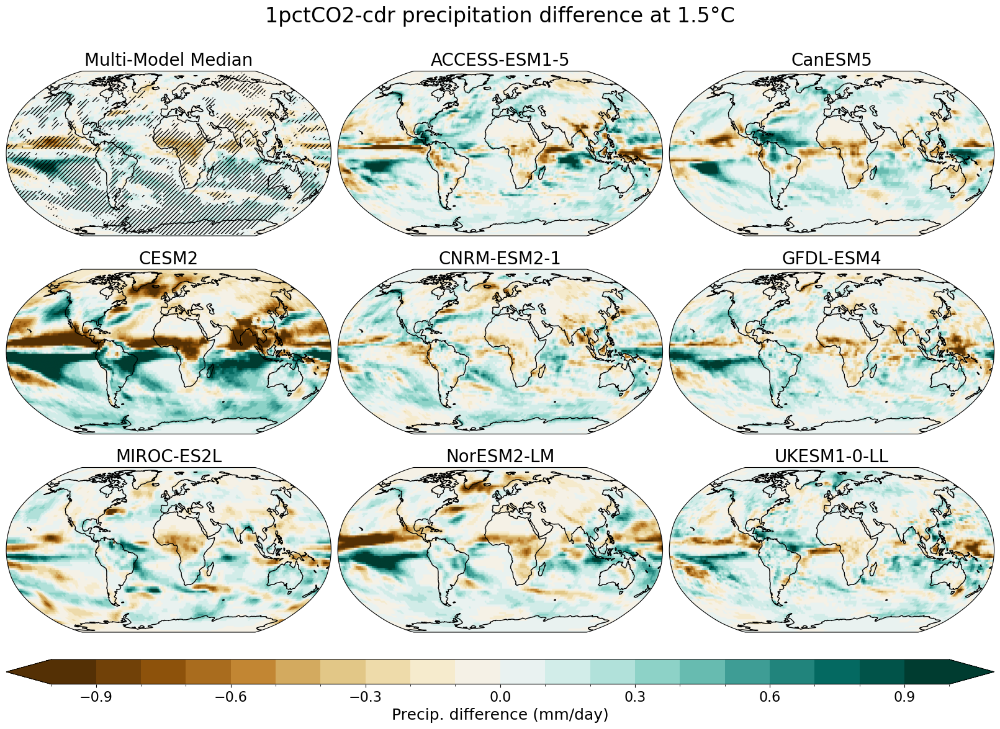

In [16]:
fig, axes = pl.plot_gwl_diff(
    diffs['pr']['diff'],
    '1pctCO2-cdr',
    varname='pr',
    gwl=1.5,
    levels=np.linspace(-1,1,21),
    cmap=cm.BrBG,
    agreement = diffs['pr']['agreement'],
    cbar_label = 'Precip. difference (mm/day)',
    suptitle = '1pctCO2-cdr precipitation difference at 1.5°C',
    figsize=(16,11)
)

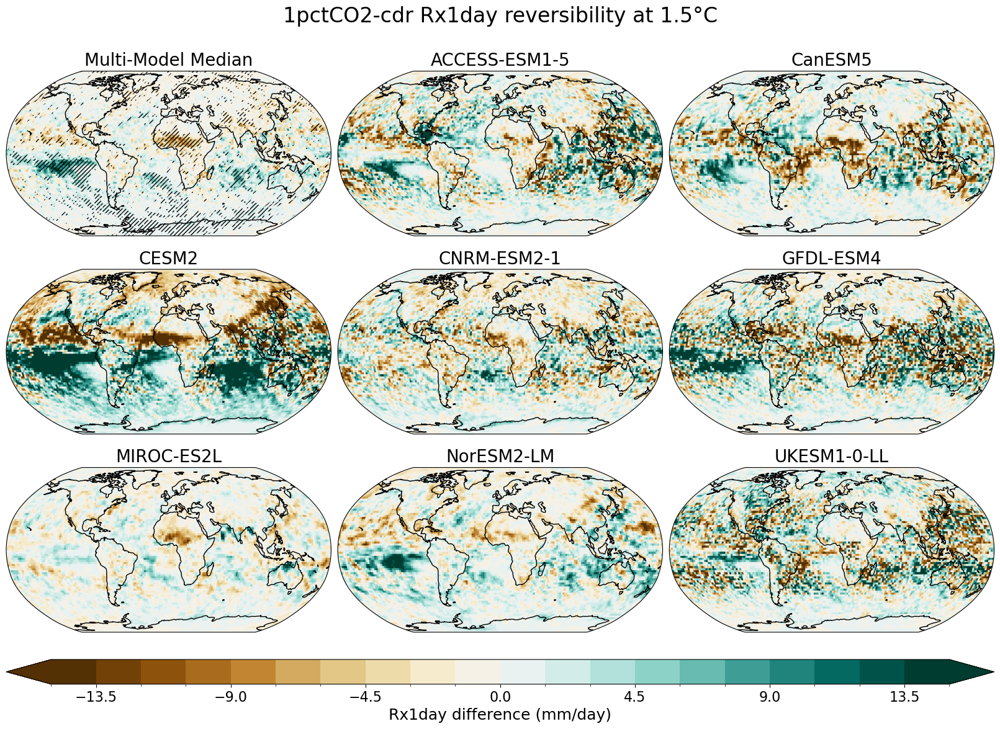

In [14]:
fig, axes = pl.plot_gwl_diff(
    diffs['rx1day']['diff'],
    '1pctCO2-cdr',
    varname='rx1day',
    gwl=1.5,
    levels=np.linspace(-15,15,21),
    cmap=cm.BrBG,
    agreement = diffs['rx1day']['agreement'],
    cbar_label = 'Rx1day difference (mm/day)',
    suptitle = '1pctCO2-cdr Rx1day reversibility at 1.5°C',
    figsize=(16,11)
)

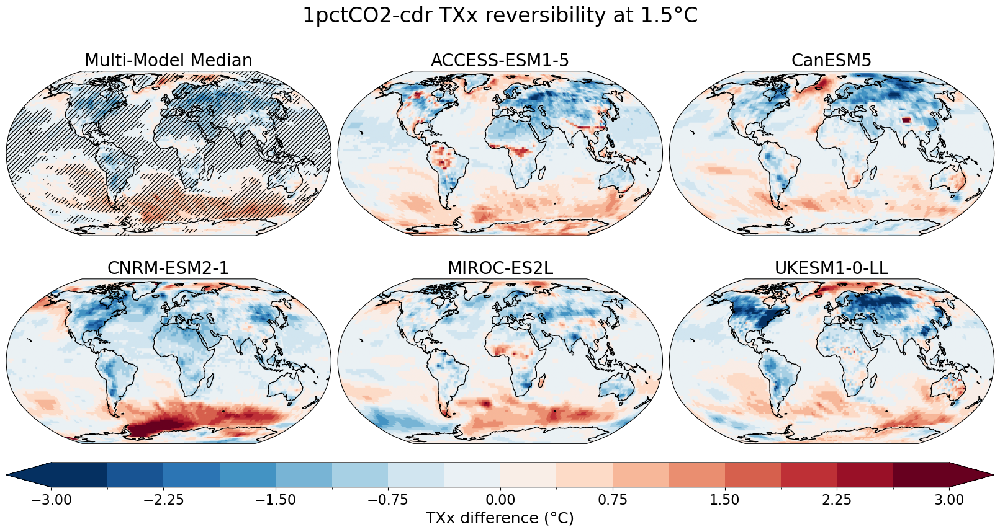

In [12]:
fig, axes = pl.plot_gwl_diff(
    diffs['txx']['diff'],
    '1pctCO2-cdr',
    varname='txx',
    gwl=1.5,
    levels=np.linspace(-3,3,17),
    cmap=cm.RdBu_r,
    agreement = diffs['txx']['agreement'],
    cbar_label = 'TXx difference (°C)',
    figsize=(16, 8),
    suptitle = '1pctCO2-cdr TXx reversibility at 1.5°C'
)

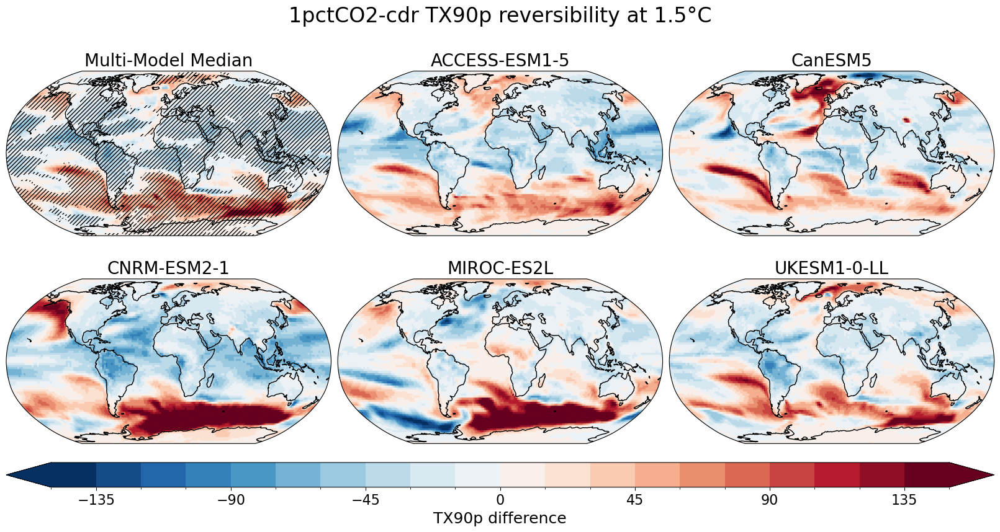

In [5]:
fig, axes = pl.plot_gwl_diff(
    diffs['tx90p']['diff'],
    '1pctCO2-cdr',
    varname='tx90p',
    gwl=1.5,
    levels=np.linspace(-150,150,21),
    cmap=cm.RdBu_r,
    agreement = diffs['tx90p']['agreement'],
    cbar_label = 'TX90p difference',
    figsize=(16, 8),
    suptitle = '1pctCO2-cdr TX90p reversibility at 1.5°C'
)

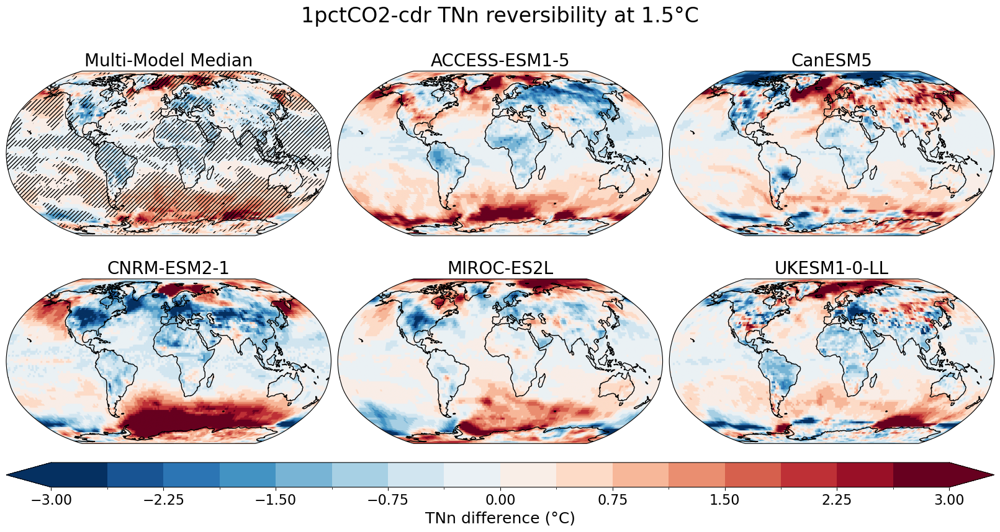

In [5]:
fig, axes = pl.plot_gwl_diff(
    diffs['tnn']['diff'],
    '1pctCO2-cdr',
    varname='tnn',
    gwl=1.5,
    levels=np.linspace(-3,3,17),
    cmap=cm.RdBu_r,
    agreement = diffs['tnn']['agreement'],
    cbar_label = 'TNn difference (°C)',
    figsize=(16, 8),
    suptitle = '1pctCO2-cdr TNn reversibility at 1.5°C'
)

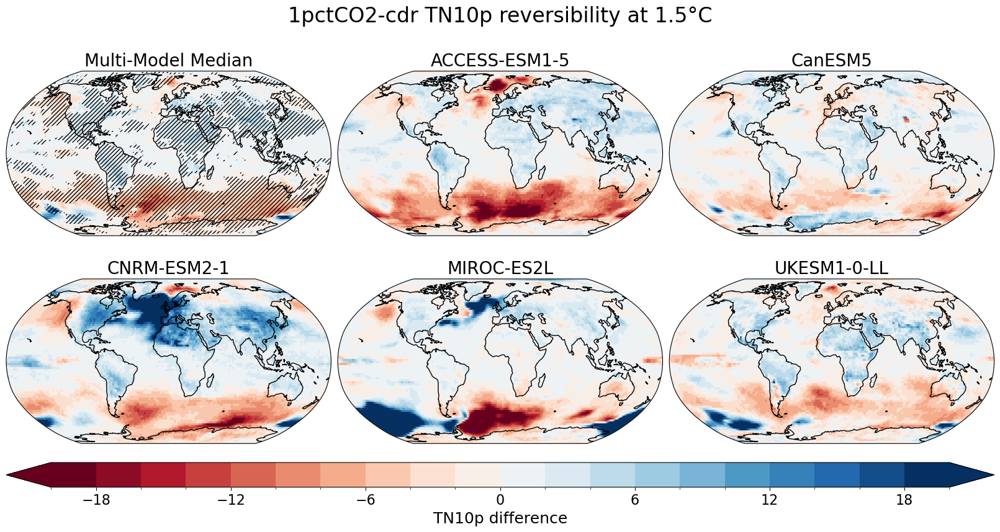

In [6]:
fig, axes = pl.plot_gwl_diff(
    diffs['tn10p']['diff'],
    '1pctCO2-cdr',
    varname='tn10p',
    gwl=1.5,
    levels=np.linspace(-20,20,21),
    cmap=cm.RdBu,
    agreement = diffs['tn10p']['agreement'],
    cbar_label = 'TN10p difference',
    figsize=(16, 8),
    suptitle = '1pctCO2-cdr TN10p reversibility at 1.5°C'
)

## Mean precip plot

In [15]:
CO2 = utils.build_co2_path()
co2 = CO2.assign_coords(year=CO2.year - 100)

In [25]:
pr_diff = {
    model: diffs['pr']['diff'][model]['1pctCO2-cdr'] for model in diffs['pr']['diff'].keys()
}
pr_diff_agreement = diffs['pr']['agreement']

In [35]:
def member_median(tree):
    """{model: {expt: {member: da}}} -> {model: {expt: da}}, median across members."""
    return {model: {expt: xr.concat(list(members.values()), dim="member").median("member")
                    for expt, members in expts.items()}
            for model, expts in tree.items()}

pr_global = member_median(utils.map_nested(partial(utils.global_mean, var="pr"), pr_anom))
pr_global_rolling = utils.map_nested(partial(stats._rolling_mean, window=21, time_dim="year"), pr_global)

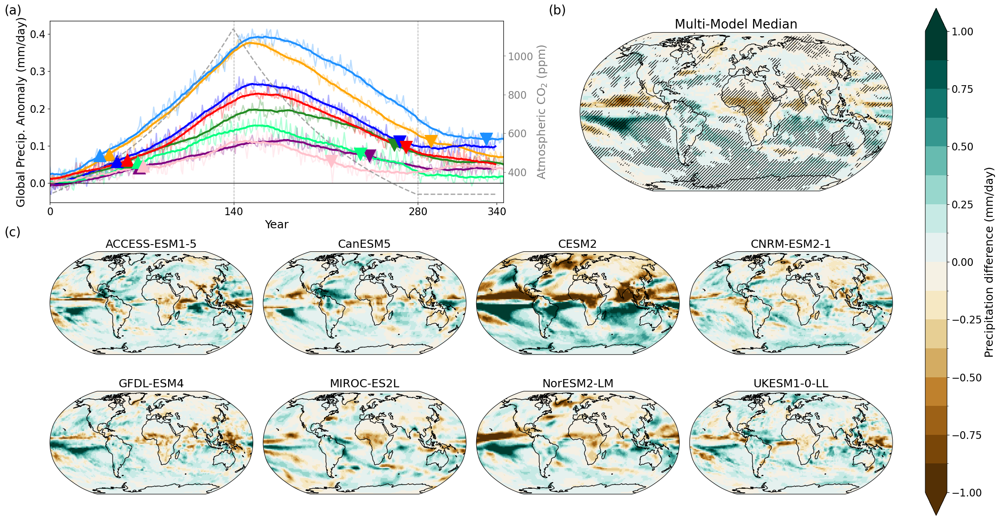

In [38]:
fig = pl.plot_gwl_diff_with_timeseries(
    pr_global_rolling,
    pr_diff,
    colour_dict,
    raw_tree=pr_global,
    crossing_years = crossing_years,
    agreement = pr_diff_agreement,
    gwl=1.5,
    co2=co2,
    cmap = cm.BrBG,
    ts_ylabel = 'Global Precip. Anomaly (mm/day)',
    cbar_label = 'Precipitation difference (mm/day)',
    levels = np.linspace(-1,1,17)
)